# Maintain Velocity Gait Analysis

This notebook loads checkpoints trained using maintain_velocity task transfer,
generates rollouts, and performs comprehensive gait analysis including:
- Video rendering
- Collision geom mapping to swing/stance barcodes
- Gait diagram plotting
- Gait cycle detection and aggregation
- Gait statistics (stride length, velocity, cadence, stance percentage)

## Imports & Environment Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import json
from pathlib import Path

import imageio
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import orbax.checkpoint as ocp
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
from scipy.signal import medfilt

from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)

%matplotlib inline
%config InlineBackend.figure_format='retina'

mpl.rcParams["figure.facecolor"] = "w"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600
mpl.rcParams["savefig.transparent"] = True
mpl.rcParams["font.size"] = 8
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial"]

## Configuration

Set the checkpoint path and other parameters here.

In [2]:
# Checkpoint path - UPDATE THIS to your checkpoint
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260204_035009_114364"
CHECKPOINT_STEP = None  # None = latest step

# Rollout parameters
EPISODE_LENGTH = 1000  # Number of steps to roll out
SEED = 42

# Rendering parameters
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50

# Output directory
OUTPUT_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint

Load the maintain_velocity checkpoint and determine the training mode.

In [3]:
# Load metadata to get config and determine mode
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
training_metadata = ckpt_info["training_metadata"]
ckpt_step = ckpt_info["step"]

mode = config["mode"]
ckpt_cfg = config["checkpoint_config"]

print(f"Loaded checkpoint at step: {ckpt_step}")
print(f"Training mode: {mode}")
print(f"Training metadata: {training_metadata}")

Loaded checkpoint at step: 41
Training mode: prior_decoder
Training metadata: {'completed_timesteps': 631439360, 'eval_step': 41, 'wandb_run_id': 'warp_speed1.0_prior_decoder_260204_035009_114364', 'run_id': '260204_035009_114364', 'mode': 'prior_decoder'}


In [4]:
# Load frozen networks from the prior checkpoint embedded in the task transfer checkpoint
prior_checkpoint_path = config["checkpoint"]["path"]
prior_checkpoint_step = config["checkpoint"]["step"]

print(f"Loading frozen networks from prior checkpoint: {prior_checkpoint_path}")

(
    encoder_params,
    prior_params,
    decoder_params,
    normalizer_params,
    _,
) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

print(f"Latent size: {latent_size}")
print(f"Proprio size: {proprio_size}")
print(f"Action size: {action_size}")

Loading frozen networks from prior checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/260131_141610_437070
Latent size: 16
Proprio size: 277
Action size: 38


## Create Environment

Create the maintain_velocity environment with the appropriate wrapper based on training mode.

In [5]:
# Create environment config from checkpoint
env_cfg = maintain_velocity.default_config()

# Set XML variant
xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.init_z = config["env"]["init_z"]
env_cfg.target_speed = config["env"]["target_speed"]

print(f"XML variant: {xml_variant}")
print(f"MuJoCo impl: {env_cfg.mujoco_impl}")
print(f"ctrl_dt: {env_cfg.ctrl_dt}")
print(f"Target speed: {env_cfg.target_speed}")

XML variant: no-tail-collisions
MuJoCo impl: warp
ctrl_dt: 0.01
Target speed: 1.0


In [6]:
# Create decoder inference function
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# Create base environment
base_env = maintain_velocity.MaintainVelocity(config=env_cfg)

# Wrap based on mode
if mode == "decoder_only":
    env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
elif mode == "scratch":
    env = FlatObsWrapper(base_env)
elif mode == "prior_decoder":
    prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
    env = PriorDecoderHighLevelWrapper(
        base_env,
        prior_fn,
        decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=config["prior_decoder"]["deterministic_prior"],
        noise_logvar=config["prior_decoder"]["noise_logvar"],
    )
else:
    raise ValueError(f"Unknown mode: {mode}")

print(f"Created wrapped environment for mode: {mode}")
print(f"Action size (policy outputs): {env.action_size}")

Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Created wrapped environment for mode: prior_decoder
Action size (policy outputs): 16


## Load Policy Parameters and Create Inference Function

In [7]:
# Create JIT-compiled reset and step functions
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

# Get observation shape from a reset
rng = jax.random.PRNGKey(0)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]

print(f"Observation size: {obs_size}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 8.55 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 1.79 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 1.86 ms  (cached)


Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 2.39 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 4.41 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 1.80 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 1.63 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 2.35 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor ca6ca3f load on device 'cuda:0' took 4.77 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.forward 3875c24 load on device 'cuda:0' took 2.35 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.support b7a7a89 load on device 'cuda:0' took 1.66 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.solver e5aab2a load on device 'cuda:0' took 3.

E0205 10:35:57.550818 1459183 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.80, %constant.179), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=47}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0205 10:36:09.038856 1459065 slow_operation_alarm.cc:140] The operation took 12.488176525s
Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.80, %constant.179), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=47}

This isn't necessarily a bug

Observation size: 331


In [8]:
# Create network factory and build abstract params for loading
normalize = running_statistics.normalize
policy_action_size = env.action_size

if mode == "scratch":
    task_obs_size = obs_size - proprio_size
    decoder_hidden_layer_sizes = tuple(ckpt_cfg["network_config"]["decoder_layer_sizes"])
    
    def network_factory(*args, **kwargs):
        return make_scratch_ppo_networks(
            task_obs_size=task_obs_size,
            proprio_size=proprio_size,
            action_size=action_size,
            latent_size=latent_size,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
    
    dummy_net = network_factory()
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
else:
    network_factory = functools.partial(
        ppo_networks.make_ppo_networks,
        policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
        value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
    )
    
    dummy_net = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)

abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

# Load trained parameters
brax_params = load_task_transfer_brax_params(
    CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
)

print("Loaded policy parameters")

Loaded policy parameters


In [9]:
# Create inference function
if mode == "scratch":
    ppo_network = network_factory()
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution
    
    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}
else:
    ppo_network = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution
    
    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

jit_inference_fn = jax.jit(inference_fn)
print("Created inference function")

Created inference function


## Generate Rollout

In [10]:
# Generate rollout following pattern from logging.py
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

print(f"Generating rollout with {EPISODE_LENGTH} steps...")
for i in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)
    
    if (i + 1) % 100 == 0:
        print(f"  Step {i + 1}/{EPISODE_LENGTH}")

print(f"Rollout complete! {len(rollout)} states collected.")

Generating rollout with 1000 steps...
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 1.98 ms  (cached)
  Step 100/1000
  Step 200/1000
  Step 300/1000
  Step 400/1000
  Step 500/1000
  Step 600/1000
  Step 700/1000
  Step 800/1000
  Step 900/1000
  Step 1000/1000
Rollout complete! 1001 states collected.


## Render Video

In [11]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera=RENDER_CAMERA,
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

print(f"Rendered {len(frames)} frames")

Rendering video with camera 'close_profile-rodent'...


100%|██████████| 1001/1001 [00:04<00:00, 209.48it/s]


Rendered 1001 frames


In [13]:
# Save video
video_path = OUTPUT_DIR / f"rollout_step{ckpt_step}.mp4"
with imageio.get_writer(str(video_path), fps=RENDER_FPS) as writer:
    for frame in frames:
        writer.append_data(frame)

print(f"Video saved to: {video_path}")

/home/mila/a/aidan.sirbu/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


Video saved to: /home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/rollout_step43.mp4


In [12]:
# Display video inline
media.show_video(frames, fps=RENDER_FPS)

This browser does not support the video tag.


## Extract Contact Data

Get collision geoms and create contact barcode (swing/stance) for each limb.

In [13]:
# Get the MuJoCo model for geom name lookups
# Access the unwrapped environment's model
unwrapped_env = env
while hasattr(unwrapped_env, "_env") or hasattr(unwrapped_env, "env"):
    if hasattr(unwrapped_env, "_env"):
        unwrapped_env = unwrapped_env._env
    elif hasattr(unwrapped_env, "env"):
        unwrapped_env = unwrapped_env.env

mj_model = unwrapped_env.mj_model
print(f"MuJoCo model loaded with {mj_model.ngeom} geoms")

MuJoCo model loaded with 101 geoms


In [14]:
# Determine MuJoCo backend from checkpoint config
mujoco_impl = env_cfg.mujoco_impl
print(f"Using MuJoCo implementation: {mujoco_impl}")

# Floor geom ID (typically 0)
FLOOR_GEOM_ID = 0

def get_contact_geom2(state, mujoco_impl):
    """Extract contact geom2 IDs for floor contacts based on MuJoCo backend.
    
    Args:
        state: Environment state from rollout
        mujoco_impl: "jax" or "warp"
        
    Returns:
        numpy array of geom2 IDs for active floor contacts (geom1 == floor)
    """
    data = state.data
    
    if mujoco_impl == "jax":
        # JAX backend: data.contact has geom1, geom2
        geom1 = np.array(data.contact.geom1)
        geom2 = np.array(data.contact.geom2)
        # Filter for floor contacts only
        floor_mask = geom1 == FLOOR_GEOM_ID
        return geom2[floor_mask]
    elif mujoco_impl == "warp":
        # Warp backend uses preallocated buffers - must filter by contact__dim > 0
        # contact__geom has shape (N, 2) with [geom1, geom2]
        contact_geom = np.array(data._impl.contact__geom)
        contact_dim = np.array(data._impl.contact__dim)
        # Filter for active contacts AND floor contacts
        active_mask = contact_dim > 0
        floor_mask = contact_geom[:, 0] == FLOOR_GEOM_ID
        combined_mask = active_mask & floor_mask
        return contact_geom[combined_mask, 1]  # Return geom2 column
    else:
        raise ValueError(f"Unsupported mujoco_impl: {mujoco_impl}")

# Extract contact geom IDs from the rollout
all_geom2 = []
for state in rollout:
    geom2 = get_contact_geom2(state, mujoco_impl)
    all_geom2.append(geom2)

# Concatenate all contacts and find unique geom IDs
all_geom2_flat = np.concatenate(all_geom2)
collision_geoms_id = np.unique(all_geom2_flat[all_geom2_flat > 0])

# Get collision geom names
collision_names = [
    mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_GEOM, int(i))
    for i in collision_geoms_id
]

print(f"Found {len(all_geom2_flat)} total floor contacts across rollout")
print(f"Collision geom IDs: {collision_geoms_id}")
print(f"Collision names: {collision_names}")

# Define limb groups based on geom names (hands and feet only, no toes/fingers)
# FL = Foot Left (hind leg)
# FR = Foot Right (hind leg)
# HL = Hand Left (front leg)
# HR = Hand Right (front leg)

def get_limb_index(geom_name):
    """Map geom name to limb index (0=FL, 1=FR, 2=HL, 3=HR).
    
    Only matches foot and hand geoms, excludes toes and fingers.
    """
    if geom_name is None:
        return -1
    # Match foot and hand only (exclude toes and fingers)
    if "foot_L" in geom_name and "toe" not in geom_name:
        return 0  # FL (hind left)
    elif "foot_R" in geom_name and "toe" not in geom_name:
        return 1  # FR (hind right)
    elif "hand_L" in geom_name and "finger" not in geom_name:
        return 2  # HL (front left)
    elif "hand_R" in geom_name and "finger" not in geom_name:
        return 3  # HR (front right)
    else:
        return -1  # Not a limb contact

# Create mapping from geom ID to limb index
geom_id_to_limb = {}
for geom_id in collision_geoms_id:
    name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_GEOM, int(geom_id))
    limb_idx = get_limb_index(name)
    if limb_idx >= 0:
        geom_id_to_limb[int(geom_id)] = limb_idx
        limb_names = {0: "FL (hind left)", 1: "FR (hind right)", 2: "HL (front left)", 3: "HR (front right)"}
        print(f"  Geom {geom_id} ({name}) -> {limb_names[limb_idx]}")

print(f"\nIncluded {len(geom_id_to_limb)} geoms for contact detection")
if len(geom_id_to_limb) < 4:
    print("Note: Some limbs may not have floor contacts in this rollout (feet/hands only, no toes/fingers)")

Using MuJoCo implementation: warp
Found 12950 total floor contacts across rollout
Collision geom IDs: [ 14  15  16  19  20  21  22  89  90  91  92  97  98  99 100]
Collision names: ['toe_L0_collision-rodent', 'toe_L1_collision-rodent', 'toe_L2_collision-rodent', 'foot_R_collision-rodent', 'toe_R0_collision-rodent', 'toe_R1_collision-rodent', 'toe_R2_collision-rodent', 'hand_L_collision-rodent', 'finger_L0_collision-rodent', 'finger_L1_collision-rodent', 'finger_L2_collision-rodent', 'hand_R_collision-rodent', 'finger_R0_collision-rodent', 'finger_R1_collision-rodent', 'finger_R2_collision-rodent']
  Geom 19 (foot_R_collision-rodent) -> FR (hind right)
  Geom 89 (hand_L_collision-rodent) -> HL (front left)
  Geom 97 (hand_R_collision-rodent) -> HR (front right)

Included 3 geoms for contact detection
Note: Some limbs may not have floor contacts in this rollout (feet/hands only, no toes/fingers)


In [15]:
# Create contact barcode: shape [4, timesteps] where 1=stance, 0=swing
num_timesteps = len(rollout)
contact_barcode = np.zeros((4, num_timesteps), dtype=np.int32)

for t, state in enumerate(rollout):
    geom2 = get_contact_geom2(state, mujoco_impl)
    for geom_id in geom2:
        geom_id = int(geom_id)
        if geom_id in geom_id_to_limb:
            limb_idx = geom_id_to_limb[geom_id]
            contact_barcode[limb_idx, t] = 1

print(f"Contact barcode shape: {contact_barcode.shape}")
print(f"Stance percentage per limb:")
limb_labels = ["FL", "FR", "HL", "HR"]
for i, label in enumerate(limb_labels):
    stance_pct = 100 * contact_barcode[i].sum() / num_timesteps
    print(f"  {label}: {stance_pct:.1f}%")

Contact barcode shape: (4, 1001)
Stance percentage per limb:
  FL: 0.0%
  FR: 0.1%
  HL: 99.2%
  HR: 74.6%


## Plot Gait Diagram

In [16]:
def plot_gait_diagram(
    contact_data,
    labels=None,
    title="Gait Diagram",
    figsize=(15, 4),
    tick_fontsize=8,
    label_fontsize=10,
    legend_fontsize=8,
    title_fontsize=10,
):
    """
    Plot swing and stance phases for limbs over time.

    Parameters:
    - contact_data: numpy array of shape (4, time) where 1 = stance, 0 = swing
    - labels: list of 4 strings for limb labels (default: ["FL", "FR", "HL", "HR"])
    - title: plot title
    - figsize: figure size tuple
    """
    if labels is None:
        labels = ["FL", "FR", "HL", "HR"]

    num_limbs, num_timesteps = contact_data.shape

    fig, ax = plt.subplots(figsize=figsize)

    # Colors for stance (contact) and swing phases
    stance_color = "#2E8B57"  # Sea green
    swing_color = "#F0F0F0"  # Light gray

    # Plot each limb's gait pattern
    for i, limb_label in enumerate(labels):
        y_pos = i

        # Create bars for stance phases
        for t in range(num_timesteps):
            if contact_data[i, t] == 1:  # Stance phase
                ax.barh(
                    y_pos,
                    1,
                    left=t,
                    height=0.8,
                    color=stance_color,
                    alpha=0.8,
                    edgecolor="none",
                )
            else:  # Swing phase
                ax.barh(
                    y_pos,
                    1,
                    left=t,
                    height=0.8,
                    color=swing_color,
                    alpha=0.8,
                    edgecolor="none",
                )

    # Customize the plot
    ax.set_yticks(range(num_limbs))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Time Steps", fontsize=label_fontsize)
    ax.set_ylabel("Limbs", fontsize=label_fontsize)
    ax.set_title(title, fontsize=title_fontsize)

    # Set tick font sizes
    ax.tick_params(axis="both", which="major", labelsize=tick_fontsize)

    # Add legend
    stance_patch = plt.Rectangle((0, 0), 1, 1, facecolor=stance_color, alpha=0.8)
    swing_patch = plt.Rectangle((0, 0), 1, 1, facecolor=swing_color, alpha=0.8)
    ax.legend(
        [stance_patch, swing_patch],
        ["Stance", "Swing"],
        loc="upper right",
        fontsize=legend_fontsize,
    )

    # Set limits and grid
    ax.set_xlim(0, num_timesteps)
    ax.set_ylim(-0.5, num_limbs - 0.5)
    ax.grid(True, alpha=0.3, axis="x")

    plt.tight_layout()
    return fig, ax

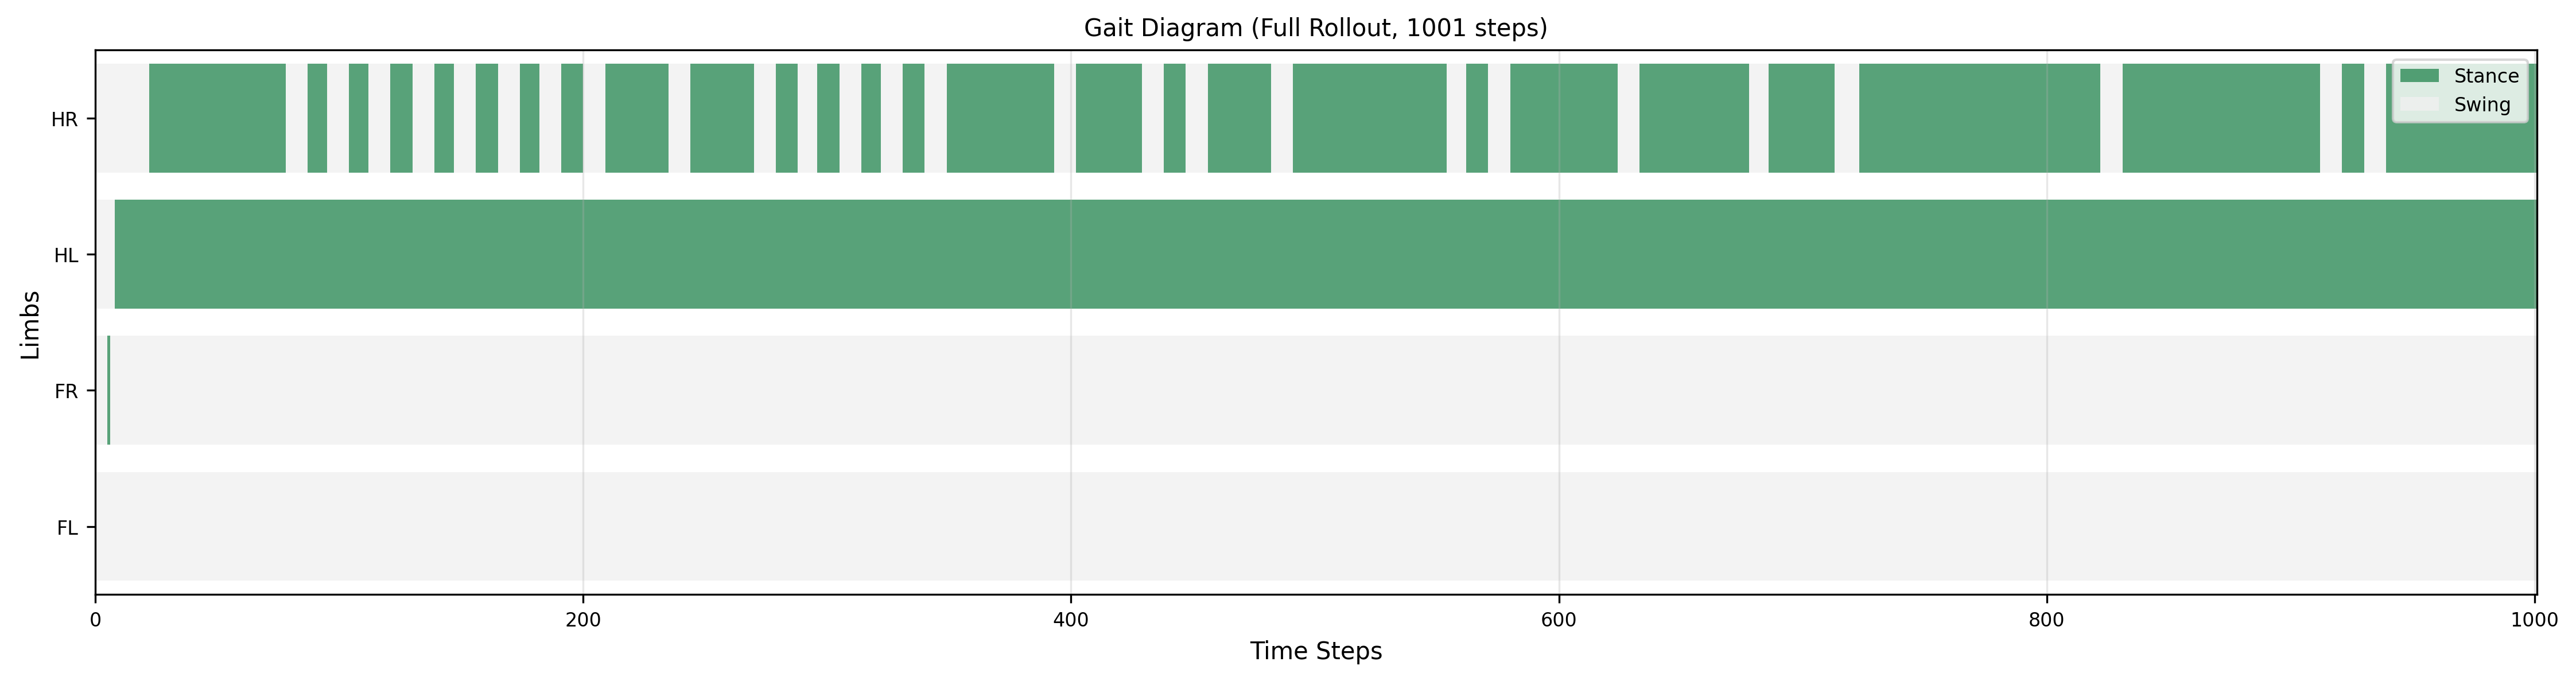

In [17]:
# Plot full gait diagram
fig, ax = plot_gait_diagram(
    contact_barcode,
    title=f"Gait Diagram (Full Rollout, {num_timesteps} steps)",
)
plt.savefig(OUTPUT_DIR / "gait_diagram_full.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Plot zoomed gait diagram (first 200 steps)
start_time = 100
end_time = 300

fig, ax = plot_gait_diagram(
    contact_barcode[:, start_time:end_time],
    title=f"Gait Diagram (Steps {start_time}-{end_time})",
)
plt.savefig(OUTPUT_DIR / "gait_diagram_zoomed.png", dpi=300, bbox_inches="tight")
plt.show()

## Smoothed Gait Diagram

Apply median filtering to reduce noise in contact detection.

In [ ]:
# Apply median filter to smooth contact barcode
smooth_kernel_size = 11
smooth_barcode = contact_barcode.copy().astype(float)

for limb_idx in range(4):
    smoothed = medfilt(smooth_barcode[limb_idx, :], kernel_size=smooth_kernel_size)
    smooth_barcode[limb_idx, :] = (smoothed > 0.5).astype(int)

smooth_barcode = smooth_barcode.astype(int)

# Plot smoothed gait diagram
fig, ax = plot_gait_diagram(
    smooth_barcode[:, start_time:end_time],
    title=f"Smoothed Gait Diagram (Steps {start_time}-{end_time}, kernel={smooth_kernel_size})",
)
plt.savefig(OUTPUT_DIR / "gait_diagram_smoothed.png", dpi=300, bbox_inches="tight")
plt.show()

## Gait Cycle Detection and Metrics

Detect individual gait cycles and compute biomechanical metrics.

In [ ]:
def find_gait_cycles(
    contact_barcode,
    limb_index=1,
    start_time=0,
    end_time=None,
    smooth=True,
    smooth_kernel_size=11,
    min_cycle_length=20,
):
    """
    Find gait cycles based on stance phase onsets.
    
    Args:
        contact_barcode: Shape [4, timesteps] contact data
        limb_index: Which limb to use for detection (0=FL, 1=FR, 2=HL, 3=HR)
        start_time: Start of analysis window
        end_time: End of analysis window (None = end of data)
        smooth: Whether to apply median filtering
        smooth_kernel_size: Kernel size for median filter
        min_cycle_length: Minimum valid cycle length in timesteps
    
    Returns:
        List of (cycle_start, cycle_end) tuples
    """
    if end_time is None:
        end_time = contact_barcode.shape[1]
    
    # Apply smoothing if requested
    if smooth:
        barcode = contact_barcode.copy().astype(float)
        smoothed = medfilt(barcode[limb_index, :], kernel_size=smooth_kernel_size)
        contacts = (smoothed[start_time:end_time] > 0.5).astype(int)
    else:
        contacts = contact_barcode[limb_index, start_time:end_time]
    
    # Find stance onsets (transitions from 0 to 1)
    stance_onsets = []
    for i in range(1, len(contacts)):
        if contacts[i-1] == 0 and contacts[i] == 1:
            stance_onsets.append(start_time + i)
    
    # Filter out onsets that are too close together
    filtered_onsets = []
    if len(stance_onsets) > 0:
        filtered_onsets.append(stance_onsets[0])
        for onset in stance_onsets[1:]:
            if onset - filtered_onsets[-1] >= min_cycle_length:
                filtered_onsets.append(onset)
    
    # Create gait cycles from consecutive stance onsets
    gait_cycles = []
    for i in range(len(filtered_onsets) - 1):
        cycle_start = filtered_onsets[i]
        cycle_end = filtered_onsets[i + 1]
        if cycle_end - cycle_start >= min_cycle_length:
            gait_cycles.append((cycle_start, cycle_end))
    
    return gait_cycles

In [ ]:
# Mapping from limb_index to foot body index (for xpos extraction)
limb_to_body_mapping = {
    0: 13,  # FL (Foot Left) -> foot_L body
    1: 17,  # FR (Foot Right) -> foot_R body
    2: 61,  # HL (Hand Left) -> hand_L body
    3: 66,  # HR (Hand Right) -> hand_R body
}

def compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=1,
    ctrl_dt=0.02,
    smooth=True,
    smooth_kernel_size=11,
):
    """
    Compute gait metrics for each gait cycle.
    
    Returns dict with:
    - stride_length_mm: List of stride lengths in mm
    - velocity_cm_per_sec: List of velocities in cm/s
    - cadence_steps_per_min: List of cadences in steps/min
    - stance_percentage: List of stance percentages
    - cycle_lengths: List of cycle lengths in timesteps
    """
    foot_body_idx = limb_to_body_mapping.get(limb_index)
    
    metrics = {
        "stride_length_mm": [],
        "velocity_cm_per_sec": [],
        "cadence_steps_per_min": [],
        "stance_percentage": [],
        "cycle_lengths": [],
    }
    
    # Get smoothed barcode for stance percentage calculation
    if smooth:
        barcode = contact_barcode.copy().astype(float)
        smoothed = medfilt(barcode[limb_index, :], kernel_size=smooth_kernel_size)
        smooth_contacts = (smoothed > 0.5).astype(int)
    else:
        smooth_contacts = contact_barcode[limb_index, :]
    
    for cycle_start, cycle_end in gait_cycles:
        cycle_length = cycle_end - cycle_start
        metrics["cycle_lengths"].append(cycle_length)
        
        # 1. Stride Length (mm)
        if foot_body_idx is not None:
            foot_pos_start = np.array(rollout[cycle_start].data.xpos[foot_body_idx])
            foot_pos_end = np.array(rollout[cycle_end].data.xpos[foot_body_idx])
            stride_length_m = np.linalg.norm(foot_pos_end - foot_pos_start)
            stride_length_mm = stride_length_m * 1000.0
            metrics["stride_length_mm"].append(stride_length_mm)
            
            # 2. Velocity (cm/sec)
            cycle_duration_sec = cycle_length * ctrl_dt
            velocity_m_per_sec = stride_length_m / cycle_duration_sec
            velocity_cm_per_sec = velocity_m_per_sec * 100.0
            metrics["velocity_cm_per_sec"].append(velocity_cm_per_sec)
            
            # 3. Cadence (steps/min)
            steps_per_sec = 1.0 / cycle_duration_sec
            cadence_steps_per_min = steps_per_sec * 60.0
            metrics["cadence_steps_per_min"].append(cadence_steps_per_min)
        
        # 4. Stance Percentage
        cycle_contacts = smooth_contacts[cycle_start:cycle_end]
        stance_pct = 100.0 * np.sum(cycle_contacts) / len(cycle_contacts)
        metrics["stance_percentage"].append(stance_pct)
    
    return metrics

In [ ]:
# Find gait cycles using FR (Front Right) limb
gait_detection_limb = 1  # FR
analysis_start = 50  # Skip initial transient
analysis_end = num_timesteps - 50  # Skip final steps

gait_cycles = find_gait_cycles(
    contact_barcode,
    limb_index=gait_detection_limb,
    start_time=analysis_start,
    end_time=analysis_end,
    smooth=True,
    smooth_kernel_size=11,
    min_cycle_length=20,
)

print(f"Found {len(gait_cycles)} gait cycles")
for i, (start, end) in enumerate(gait_cycles[:5]):
    print(f"  Cycle {i+1}: steps {start}-{end} (length: {end-start})")
if len(gait_cycles) > 5:
    print(f"  ... and {len(gait_cycles) - 5} more cycles")

In [ ]:
# Compute gait metrics
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]

gait_metrics = compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=gait_detection_limb,
    ctrl_dt=ctrl_dt,
    smooth=True,
    smooth_kernel_size=11,
)

print("\nGait Metrics Summary:")
print("-" * 50)

if gait_metrics["stride_length_mm"]:
    print(f"Stride Length: {np.mean(gait_metrics['stride_length_mm']):.1f} +/- {np.std(gait_metrics['stride_length_mm']):.1f} mm")
    print(f"Velocity: {np.mean(gait_metrics['velocity_cm_per_sec']):.1f} +/- {np.std(gait_metrics['velocity_cm_per_sec']):.1f} cm/s")
    print(f"Cadence: {np.mean(gait_metrics['cadence_steps_per_min']):.1f} +/- {np.std(gait_metrics['cadence_steps_per_min']):.1f} steps/min")

print(f"Stance Percentage: {np.mean(gait_metrics['stance_percentage']):.1f} +/- {np.std(gait_metrics['stance_percentage']):.1f} %")
print(f"Cycle Length: {np.mean(gait_metrics['cycle_lengths']):.1f} +/- {np.std(gait_metrics['cycle_lengths']):.1f} timesteps")

## Plot Gait Metrics Distributions

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Stride Length
if gait_metrics["stride_length_mm"]:
    axes[0, 0].hist(gait_metrics["stride_length_mm"], bins=15, edgecolor="black", alpha=0.7)
    axes[0, 0].axvline(np.mean(gait_metrics["stride_length_mm"]), color="red", linestyle="--", label="Mean")
    axes[0, 0].set_xlabel("Stride Length (mm)")
    axes[0, 0].set_ylabel("Count")
    axes[0, 0].set_title("Stride Length Distribution")
    axes[0, 0].legend()

# Velocity
if gait_metrics["velocity_cm_per_sec"]:
    axes[0, 1].hist(gait_metrics["velocity_cm_per_sec"], bins=15, edgecolor="black", alpha=0.7)
    axes[0, 1].axvline(np.mean(gait_metrics["velocity_cm_per_sec"]), color="red", linestyle="--", label="Mean")
    axes[0, 1].set_xlabel("Velocity (cm/s)")
    axes[0, 1].set_ylabel("Count")
    axes[0, 1].set_title("Velocity Distribution")
    axes[0, 1].legend()

# Cadence
if gait_metrics["cadence_steps_per_min"]:
    axes[1, 0].hist(gait_metrics["cadence_steps_per_min"], bins=15, edgecolor="black", alpha=0.7)
    axes[1, 0].axvline(np.mean(gait_metrics["cadence_steps_per_min"]), color="red", linestyle="--", label="Mean")
    axes[1, 0].set_xlabel("Cadence (steps/min)")
    axes[1, 0].set_ylabel("Count")
    axes[1, 0].set_title("Cadence Distribution")
    axes[1, 0].legend()

# Stance Percentage
axes[1, 1].hist(gait_metrics["stance_percentage"], bins=15, edgecolor="black", alpha=0.7)
axes[1, 1].axvline(np.mean(gait_metrics["stance_percentage"]), color="red", linestyle="--", label="Mean")
axes[1, 1].set_xlabel("Stance Percentage (%)")
axes[1, 1].set_ylabel("Count")
axes[1, 1].set_title("Stance Percentage Distribution")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gait_metrics_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Plot cycle-by-cycle metrics
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

cycle_numbers = np.arange(1, len(gait_cycles) + 1)

# Stride Length over cycles
if gait_metrics["stride_length_mm"]:
    axes[0, 0].plot(cycle_numbers, gait_metrics["stride_length_mm"], "o-", markersize=4)
    axes[0, 0].axhline(np.mean(gait_metrics["stride_length_mm"]), color="red", linestyle="--", alpha=0.7)
    axes[0, 0].set_xlabel("Cycle Number")
    axes[0, 0].set_ylabel("Stride Length (mm)")
    axes[0, 0].set_title("Stride Length per Cycle")
    axes[0, 0].grid(True, alpha=0.3)

# Velocity over cycles
if gait_metrics["velocity_cm_per_sec"]:
    axes[0, 1].plot(cycle_numbers, gait_metrics["velocity_cm_per_sec"], "o-", markersize=4)
    axes[0, 1].axhline(np.mean(gait_metrics["velocity_cm_per_sec"]), color="red", linestyle="--", alpha=0.7)
    axes[0, 1].set_xlabel("Cycle Number")
    axes[0, 1].set_ylabel("Velocity (cm/s)")
    axes[0, 1].set_title("Velocity per Cycle")
    axes[0, 1].grid(True, alpha=0.3)

# Cycle length over cycles
axes[1, 0].plot(cycle_numbers, gait_metrics["cycle_lengths"], "o-", markersize=4)
axes[1, 0].axhline(np.mean(gait_metrics["cycle_lengths"]), color="red", linestyle="--", alpha=0.7)
axes[1, 0].set_xlabel("Cycle Number")
axes[1, 0].set_ylabel("Cycle Length (timesteps)")
axes[1, 0].set_title("Cycle Length per Cycle")
axes[1, 0].grid(True, alpha=0.3)

# Stance percentage over cycles
axes[1, 1].plot(cycle_numbers, gait_metrics["stance_percentage"], "o-", markersize=4)
axes[1, 1].axhline(np.mean(gait_metrics["stance_percentage"]), color="red", linestyle="--", alpha=0.7)
axes[1, 1].set_xlabel("Cycle Number")
axes[1, 1].set_ylabel("Stance Percentage (%)")
axes[1, 1].set_title("Stance Percentage per Cycle")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gait_metrics_per_cycle.png", dpi=300, bbox_inches="tight")
plt.show()

## Summary Statistics Table

In [ ]:
# Create summary table
import pandas as pd

summary_data = {
    "Metric": [],
    "Mean": [],
    "Std": [],
    "Min": [],
    "Max": [],
    "N": [],
}

metrics_info = [
    ("Stride Length (mm)", gait_metrics["stride_length_mm"]),
    ("Velocity (cm/s)", gait_metrics["velocity_cm_per_sec"]),
    ("Cadence (steps/min)", gait_metrics["cadence_steps_per_min"]),
    ("Stance Percentage (%)", gait_metrics["stance_percentage"]),
    ("Cycle Length (timesteps)", gait_metrics["cycle_lengths"]),
]

for name, values in metrics_info:
    if values:
        summary_data["Metric"].append(name)
        summary_data["Mean"].append(f"{np.mean(values):.2f}")
        summary_data["Std"].append(f"{np.std(values):.2f}")
        summary_data["Min"].append(f"{np.min(values):.2f}")
        summary_data["Max"].append(f"{np.max(values):.2f}")
        summary_data["N"].append(len(values))

summary_df = pd.DataFrame(summary_data)
print("\nGait Metrics Summary")
print("=" * 80)
print(summary_df.to_string(index=False))

# Save to CSV
summary_df.to_csv(OUTPUT_DIR / "gait_metrics_summary.csv", index=False)
print(f"\nSummary saved to: {OUTPUT_DIR / 'gait_metrics_summary.csv'}")

In [ ]:
# Display as styled table
summary_df